# ACCESS-OM3 depth-latitude temperature and temperature difference from WOA23

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-25km-paper-1/issues/11

OM2 paper figure 12 https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/temperature_biases/zonal_temp_salt_bias.ipynb

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_iaf+wombatlite-test1-e1de2a94/experiment_datastore.json"
papermill = True
cwd = (
    "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100A/"
)
nbname = "temp-salt-vs-depth-latitude.ipynb"


In [3]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from model_agnostic import patch_broken_conda_env
from exptdata_access import guess_experiment_from_esm_file
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [4]:
IAF = esm_file.find('iaf') > 0
IAF

True

In [5]:
import os
import numpy as np
import xarray as xr
import cftime
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import gsw
import intake
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib as mpl
from distributed import Client
import cmocean
import cartopy.crs as ccrs
import cartopy.feature as cft
from shapely import geometry
from textwrap import wrap
from tqdm.notebook import tqdm
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default

In [6]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [7]:
client = Client(threads_per_worker=1)
from model_agnostic import patch_dask_workers
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:35553,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:40815,Total threads: 1
Dashboard: http://127.0.0.1:44885/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:42327,


## Define regions

Global maxy changed from 90 to 65 to omit tripolar region


Text(0.5, 1.0, 'Regions (BUG: incorrect shapes north of 65°N)')

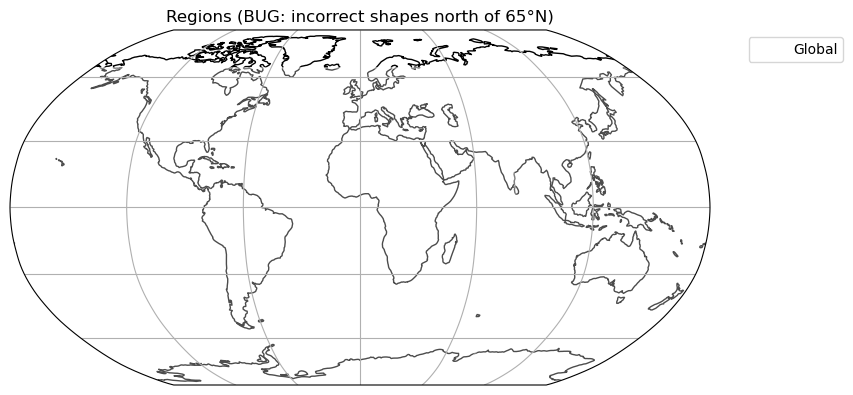

In [8]:
regions = { # [minx, maxx, miny, maxy], using model longitude range (-280 to 80)
    "Global": [-280, 80, -90, 90],
    # "Arctic": [-280, 80, 65, 90],
    # "Southern Ocean": [-280, 80, -82, -63],
    # "ACC": [-280, 80, -63, -45],
    # "Southern Pacific": [-210, -70, -45, -20],
    # "Tropical Pacific": [-240, -100, -20, 20],
    # "North Pacific": [-240, -100, 20, 65],
    # "South Atlantic": [-60, 20, -45, -20],
    # "Tropical Atlantic": [-70, 20, -20, 20],
    # "North Atlantic": [-100, 0, 20, 65],
    # "Indian": [30, 120, -45, 20],
    # "Aegean Sea": [18, 27.5, 34, 44],
    # "Black Sea": [27.5, 43, 40.5, 48],
    # "Baltic Sea": [13, 30, 53, 58],
    # "Mediterranean Sea": [0, 35, 31, 41],
    # "Red Sea": [33, 44, 12, 29],
    # "Persian Gulf": [47, 56, 24, 31],
    # "White Sea": [31, 41, 63, 68],
}
regions = {k: dict(zip(["minx", "maxx", "miny", "maxy"], v)) for k, v in regions.items()}  # convert to dicts

for r, d in regions.items():
    for k, x in d.items():
        if k in ["minx", "maxx"] and x != max(-280, min(x, 80)):
            raise ValueError(f"{r} {k} = {x} is outside the range -280 to 80")
        if k in ["miny", "maxy"] and x > 65:
            print(f"{r} {k} changed from {x} to 65 to omit tripolar region")
            d[k] = 65
            

fig = plt.figure(figsize=(10, 4))

colors = mpl.color_sequences['tab20']
try:  # set Global color to white 
    colors[list(regions.keys()).index("Global")] = (1, 1, 1)
except ValueError:
    pass

ax = plt.axes(position=[0.05,0.05,0.7,0.9], projection=ccrs.Robinson())
ax.coastlines(resolution="110m")
ax.gridlines(draw_labels=False)

legend_elements = []
for i, (region, limits) in enumerate(regions.items()):
    ax.add_geometries([geometry.box(**limits)], crs=ccrs.PlateCarree(), color=colors[i], alpha=0.3)
    legend_elements.append(Patch(color=colors[i], alpha=0.3, label=region))

ax.legend(handles=legend_elements, bbox_to_anchor=(1.2, 1.00))
plt.title("Regions (BUG: incorrect shapes north of 65°N)")

## Load data from ACCESS-OM3

In [9]:
from exptdata_access import get_exptname_from_path
om3exptname = get_exptname_from_path(esm_file)
catalogs = [
                esm_file,
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm1-d968c801/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm2-5dc49da6/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm3-da330542/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm4-9fd08880/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm5-9b5dbfa9/datastore.json',
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
            ]
catalogs

['/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_iaf+wombatlite-test1-e1de2a94/experiment_datastore.json']

In [10]:
om3datastores = { get_exptname_from_path(c):
               intake.open_esm_datastore(c,
                                         columns_with_iterables=[
                                            "variable",
                                            "variable_long_name",
                                            "variable_standard_name",
                                            "variable_cell_methods",
                                            "variable_units"]
                                        )
              for c in catalogs }
om3datastores

{'MC_100km_jra_iaf+wombatlite-test1-e1de2a94': <experiment_datastore catalog with 24 dataset(s) from 11531 asset(s)>}

In [11]:
om3varnames = [ 'thetao', 'so' ]  # potential temperature and practical salinity

om3vars = {
    vname: {expt: ds.search(variable=vname).to_dask(
                xarray_open_kwargs = dict(
                    chunks={"xh": -1, "yh": "auto", "z_l": "auto"},
                    decode_timedelta=True
                )
            )[vname]
            for expt, ds in om3datastores.items()
          }
    for vname in om3varnames
    }

# omit latitudes with grid bug in this run https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
for vname, d in om3vars.items():
    try:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yh=slice(10, None))
    except ValueError:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yq=slice(10, None))
    except KeyError:
        pass

if IAF or "cm3" in om3exptname.lower():  # common calendar for obs overlays
    for vname, d in om3vars.items():
        for expt in d:
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

## Load data from ACCESS-OM2
use control - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258#p-747-ryf-7

In [12]:
if model_name == "ACCESS-CM3":
    data_name = 'ACCESS-CM2'
    om2exptname = 'cj877'  # CM2 control archive on /g/data/p73 (same reference as pPV.ipynb)
else:
    data_name = 'ACCESS-OM2'
    if IAF:
        om2exptname = '025deg_jra55_iaf_omip2_cycle1'
    else:
        om2exptname = '025deg_jra55_ryf9091_gadi'  # monthly temp only for 1900-1903, and 2300-, with annual data in the gap
    om2frequency = "1mon" if IAF else "1yr"  # 025deg_jra55_ryf9091_gadi only has pot_temp as annual means
    om2datastores = {om2exptname: intake.cat.access_nri[om2exptname]}

In [13]:
if model_name == "ACCESS-CM3":
    # Reference: ACCESS-CM2 cj877 control archive (same source as pPV.ipynb,
    # Overturning_in_ACCESS_OM3.ipynb, and temp-salt-vs-depth-time.ipynb).
    # Limit to the last 600 months to match the CM3 record length; each
    # cj877 file holds 6 months.
    from pathlib import Path
    cm2_dir = Path("/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn")
    n_months = 600
    om2varnames = [ 'temp', 'salt' ]

    def _load_cm2(varname):
        files = sorted(cm2_dir.glob(f"ocean-3d-{varname}-1-monthly-mean-ym_*.nc"))
        if not files:
            raise FileNotFoundError(f"No cj877 monthly files found for {varname!r}")
        files = files[-((n_months + 5) // 6):]
        ds = xr.open_mfdataset(
            files,
            combine="by_coords",
            parallel=True,
            chunks={"time": 1, "xt_ocean": -1, "yt_ocean": -1, "st_ocean": -1},
            decode_timedelta=True,
            use_cftime=True,  # cj877 model years can't be datetime64
            data_vars="minimal", coords="minimal", compat="override",
        )
        return ds[varname]

    om2vars = { vname: {om2exptname: _load_cm2(vname)} for vname in om2varnames }
else:
    om2varnames = [ 'pot_temp', 'salt' ]  # potential temperature and practical salinity

    om2vars = {
        vname: {expt: ds.search(variable=vname, frequency=om2frequency).to_dask(
                    xarray_open_kwargs = dict(
                        chunks={"xt_ocean": -1, "yt_ocean": "auto", "st_ocean" : "auto"},
                        decode_timedelta=True
                    )
                )[vname]
                for expt, ds in om2datastores.items()
              }
        for vname in om2varnames
        }

    if IAF:
        for vname, d in om2vars.items():
            for expt in d:
                try:
                    d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
                except KeyError:
                    pass

    for expt, da in om2vars['pot_temp'].items():
        try:
            om2vars['pot_temp'][expt] = om2vars['pot_temp'][expt] - 273.15  # convert to degC
            om2vars['pot_temp'][expt].attrs['units'] = 'degC'
        except KeyError:
            pass

## Set time range

In [14]:
from model_agnostic import years_window, year_slice

lasttime = []
for vname, d in om3vars.items():
    for expt, da in d.items():
        lasttime.append(da.time.values[-1])
for vname, d in om2vars.items():
    for expt, da in d.items():
        lasttime.append(da.time.values[-1])

if IAF or "cm3" in om3exptname.lower():  # robust window relative to the data's own last timestep
    # datestop = cftime.DatetimeProlepticGregorian(2018, 12, 31, 12, 0, 0, 0, has_year_zero=True)  # to match OM2 IAF run
    datestop = min(lasttime) # earliest final date in data
    datelist = list(cftime.to_tuple(datestop))
    datelist[0] -= 25  # last 25 years
    datestart = cftime.datetime(*datelist, calendar=datestop.calendar)
    # bracket to start/end of year
    datestart = cftime.datetime(cftime.to_tuple(datestart)[0],  1, 1, calendar=datestop.calendar)
    datestop  = cftime.datetime(cftime.to_tuple(datestop)[0], 12, 31, 23, 59, 59, calendar=datestop.calendar)
    timerange = slice(datestart, datestop)
    om2timerange = timerange
    period = f'{datestart.strftime("%Y-%m-%d")} - {datestop.strftime("%Y-%m-%d")}'
else:
    # RYF: calendar years are arbitrary, so use the last (up to) 25 complete years of OM3,
    # and the same model years of the OM2 RYF control where it has them
    om3window = years_window(om3vars[om3varnames[0]][om3exptname].time, 25)
    om2window = years_window(om2vars[om2varnames[0]][om2exptname].time, 25, within=om3window)
    timerange = year_slice(om3window)
    om2timerange = year_slice(om2window)
    period = f'{om3window[0]}-{om3window[1]}'
    if om2window != om3window:
        period += f' ({data_name}: {om2window[0]}-{om2window[1]})'

# timerange = slice(None, None)

print('timerange =', timerange)
print('om2timerange =', om2timerange)

timerange = slice(cftime.datetime(1993, 1, 1, 0, 0, 0, 0, calendar='proleptic_gregorian', has_year_zero=True), cftime.datetime(2018, 12, 31, 23, 59, 59, 0, calendar='proleptic_gregorian', has_year_zero=True), None)
om2timerange = slice(cftime.datetime(1993, 1, 1, 0, 0, 0, 0, calendar='proleptic_gregorian', has_year_zero=True), cftime.datetime(2018, 12, 31, 23, 59, 59, 0, calendar='proleptic_gregorian', has_year_zero=True), None)


## Calculate zonal mean for each region

In [15]:
%%time
om3vars_mean = {
    region:
    {
        vname: {
                expt: da.sel(yh=slice(b['miny'], b['maxy']))\
                        .sel(xh=slice(b['minx'], b['maxx']))\
                        .sel(time=timerange)\
                        .mean('xh').mean('time').load()
                for expt, da in tqdm(vdatadict.items(), desc=f'      {vname} experiments', )
              }
        for vname, vdatadict in tqdm(om3vars.items(), desc=f'   {region} variables')
    }
    for region, b in tqdm(regions.items(), desc='regions')
}

regions:   0%|          | 0/1 [00:00<?, ?it/s]

   Global variables:   0%|          | 0/2 [00:00<?, ?it/s]

      thetao experiments:   0%|          | 0/1 [00:00<?, ?it/s]

      so experiments:   0%|          | 0/1 [00:00<?, ?it/s]

CPU times: user 4.57 s, sys: 2.89 s, total: 7.46 s
Wall time: 12.7 s


In [16]:
%%time
om2vars_mean = {
    region:
    {
        vname: {
                expt: da.sel(yt_ocean=slice(b['miny'], b['maxy']))\
                        .sel(xt_ocean=slice(b['minx'], b['maxx']))\
                        .sel(time=om2timerange)\
                        .mean('xt_ocean').mean('time').load()
                for expt, da in tqdm(vdatadict.items(), desc=f'      {vname} experiments', )
              }
        for vname, vdatadict in tqdm(om2vars.items(), desc=f'   {region} variables')
    }
    for region, b in tqdm(regions.items(), desc='regions')
}

regions:   0%|          | 0/1 [00:00<?, ?it/s]

   Global variables:   0%|          | 0/2 [00:00<?, ?it/s]

      pot_temp experiments:   0%|          | 0/1 [00:00<?, ?it/s]

      salt experiments:   0%|          | 0/1 [00:00<?, ?it/s]

CPU times: user 20.5 s, sys: 17.5 s, total: 38 s
Wall time: 1min 28s


## Load data from WOA

NB: we're taking a mean of the monthly means. This reduces seasonal bias relative to the annual mean WOA (I think!), but will also involve more interpolated values.

The alternative would be to use the WOA annual mean `/g/data/ik11/observations/woa23/woa23_decav_[ts]00_04.nc` but this needs to be converted to the appropriate temperature and salinity, and regridded to model grid.


In [17]:
# fragile! obs_file_pattern depends on model run!
# obs_file_pattern = "/g/data/ik11/inputs/access-om3/woa23/025/2025.10.24/woa23_ts_*"
om3mask = np.isfinite(om3vars['thetao'][om3exptname].isel(time=0)).load()

obs_file_pattern = "/g/data/ik11/inputs/access-om3/woa23/025/2026.06.11/woa23_ts_*"  # for MC_25km_jra_iaf+wombatlite-test4-d28e0359

# WOA23 products by model grid shape: the obs is masked onto the model grid
# below (.where(om3mask)), so the two must have identical (yh, xh). Selecting by
# shape rather than hard-coding one resolution lets this notebook run at both
# 25km and 100km; an unrecognised grid falls back to the default set above.
woa23_products = {
    (1152, 1440): "/g/data/ik11/inputs/access-om3/woa23/025/2026.06.11/woa23_ts_*",   # 25km / 0.25deg grid
    (324, 360):   "/g/data/ik11/inputs/access-om3/woa23/1deg/2026.02.17/woa23_ts_*",  # 100km / 1deg grid (324 rows)
    (300, 360):   "/g/data/ik11/inputs/access-om3/woa23/1deg/2025.10.24/woa23_ts_*",  # 100km / 1deg grid (300 rows)
    (3672, 4320): "/g/data/ik11/inputs/access-om3/woa23/8km/2026.09.17/woa23_ts_*",   # 8km grid
    (3360, 4320): "/g/data/vk83/prerelease/configurations/inputs/access-om3/mom/initial_conditions/global.8km/2026.10.07/woa23_ts_*_mom.nc",  # 8km grid (hgrid 2026.10.07)
}
_grid_shape = (om3mask.sizes["yh"], om3mask.sizes["xh"])
obs_file_pattern = woa23_products.get(_grid_shape, obs_file_pattern)
print(f"model grid (yh, xh) = {_grid_shape} -> {obs_file_pattern}")



ds_obs = xr.open_mfdataset(
        obs_file_pattern,
        chunks={"time": -1})\
    .cf.mean("time")\
    .rename({'lon': 'xh', 'lat': 'yh', 'depth': 'z_l'})\
    .where(om3mask)  # mask out interpolated values at dry points in model

woa23vars = { k: ds_obs[k] for k in ["ptemp", "salt"] } # for OM3: potential temperature and practical salinity

# calculate zonal mean for each region
woa23vars_mean = {
    region:
    {
        vname: da.cf.sel( latitude=slice(b['miny'], b['maxy']))\
                 .cf.sel(longitude=slice(b['minx'], b['maxx']))\
                 .cf.mean('longitude')\
                 .load()
        for vname, da in tqdm(woa23vars.items(), desc=f'   {region} variables')
    }
    for region, b in tqdm(regions.items(), desc='regions')
}

model grid (yh, xh) = (324, 360) -> /g/data/ik11/inputs/access-om3/woa23/1deg/2026.02.17/woa23_ts_*


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccbc7770b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccb1cd06b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccb1cc3d40>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccb1ed7ec0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccb1cb5430>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccb1eb4290>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14ccb08def60>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


regions:   0%|          | 0/1 [00:00<?, ?it/s]

   Global variables:   0%|          | 0/2 [00:00<?, ?it/s]

In [18]:
# fragile! obs_file_pattern depends on model run!
obs_file_pattern = "/g/data/ik11/observations/woa13/025_KDS50/woa13_ts_??_mom025.nc"  # for 025deg_jra55_iaf_omip2_cycle1

om2mask = np.isfinite(om2vars[om2varnames[0]][om2exptname].isel(time=0)).load()

ds_obs = xr.open_mfdataset(
        obs_file_pattern,
        chunks={"time": -1},
        decode_times=xr.coders.CFDatetimeCoder(use_cftime=True))\
    .cf.mean("time")\
    .rename({'GRID_X_T': 'xt_ocean', 'GRID_Y_T': 'yt_ocean', 'ZT': 'st_ocean'})

# fix to handle slightly different st_ocean precision
ds_obs.coords['st_ocean'] = om2mask.coords['st_ocean'].values
       
ds_obs = ds_obs.where(om2mask)  # mask out interpolated values at dry points in model

woa13vars = { k: ds_obs[k] for k in ["temp", "salt"] } # for OM2: potential temperature and practical salinity

# calculate zonal mean for each region
woa13vars_mean = {
    region:
    {
        vname: da.cf.sel( latitude=slice(b['miny'], b['maxy']))\
                 .cf.sel(longitude=slice(b['minx'], b['maxx']))\
                 .cf.mean('longitude')\
                 .load()
        for vname, da in tqdm(woa13vars.items(), desc=f'   {region} variables')
    }
    for region, b in tqdm(regions.items(), desc='regions')
}

regions:   0%|          | 0/1 [00:00<?, ?it/s]

   Global variables:   0%|          | 0/2 [00:00<?, ?it/s]

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 58.09 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 58.09 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


### alternative approach for WOA data - not used

Would need to interpolate WOA data onto model grid

## Regridders
See https://github.com/aekiss/ice_analysis/blob/main/ice_maps.ipynb

## Plot zonal means for each region

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100A/mkmd/temp-salt-vs-depth-latitude_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100A/mkmd/temp-salt-vs-depth-latitude.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_F100A/mkmd/temp-salt-vs-depth-latitude.md successfully.


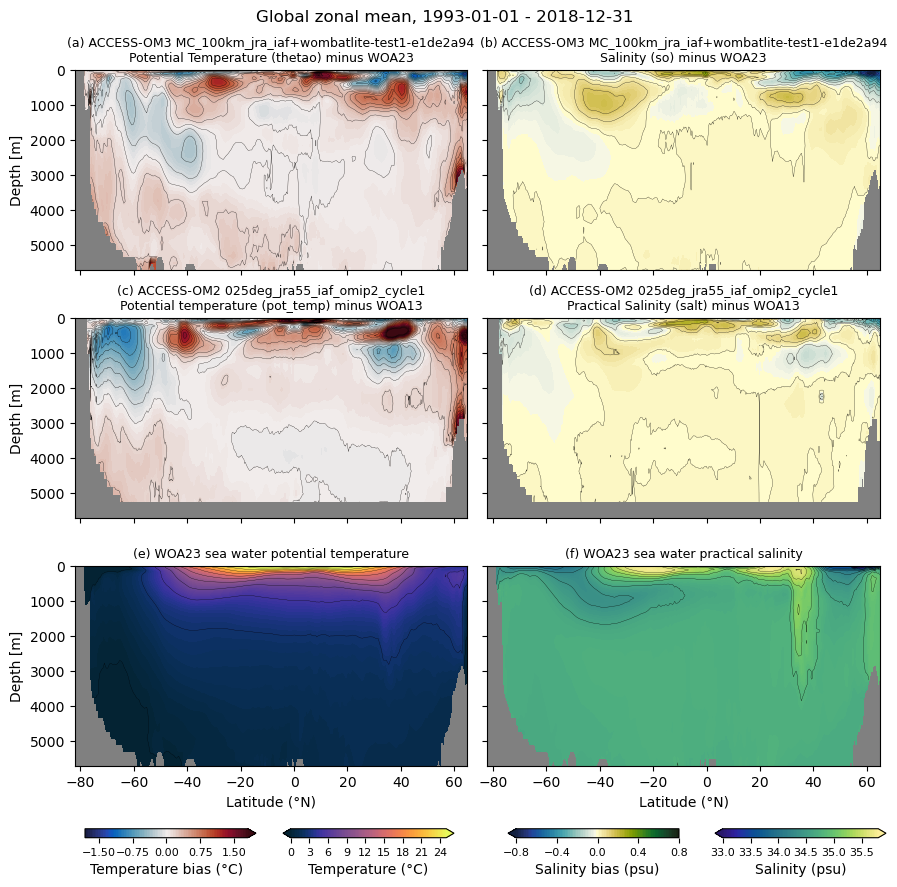

In [19]:
for region, d in om3vars_mean.items():
    om3variable = "thetao"  # potential temperature
    om2variable = "temp" if model_name == "ACCESS-CM3" else "pot_temp"  # potential temperature
    woa23variable = "ptemp"  # potential temperature
    woa13variable = "temp"  # potential temperature

    npanels = 2 * (len(d[om3variable]) + len(om2vars_mean[region][om2variable]) + 1)
    nrows = (npanels+1)//2
    fig, axs = plt.subplots(nrows, 2,
                            figsize=(9, 3*nrows),
                            sharex=True, sharey=True)
    fig.suptitle(f'{region} zonal mean, {period}', y=0.98)

    # Column 1: Temperature
    cmap = cmocean.cm.balance

    vlim = -1
    for da in d[om3variable].values():
        vlim = max(vlim, np.abs(da - woa23vars_mean[region][woa23variable]).max().data)
    for da in om2vars_mean[region][om2variable].values():
        vlim = max(vlim, np.abs(da - woa13vars_mean[region][woa13variable]).max().data)

    vlim = 1.8 # to match Kiss et al 2020 fig 12

    # ACCESS-OM3
    for i, (expt, da) in enumerate(d[om3variable].items()):
        # print(da)
        plt.subplot(nrows, 2, 2*i+1).set_facecolor('gray')  # gray land points
        p = (da - woa23vars_mean[region][woa23variable]).plot.contourf(
            levels=101, vmin=-vlim, vmax=vlim, cmap=cmap, add_colorbar=False,
        )
        (da - woa23vars_mean[region][woa23variable]).plot.contour(
            levels=25, vmin=-vlim, vmax=vlim, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
        )
        plt.gca().set_ylim([0, None])
        plt.gca().invert_yaxis()
        plt.title(f"({chr(ord('a')+2*i)}) ACCESS-OM3 {expt}\n{da.attrs['long_name']} ({om3variable}) minus WOA23", fontsize=9)
        plt.xlabel('')
        plt.ylabel('Depth [m]')

    # ACCESS-OM2
    for i, (expt, da) in enumerate(om2vars_mean[region][om2variable].items(), start=i+1):
        plt.subplot(nrows, 2, 2*i+1).set_facecolor('gray')  # gray land points
        p1 = (da - woa13vars_mean[region][woa13variable]).plot.contourf(
            levels=101, vmin=-vlim, vmax=vlim, cmap=cmap, add_colorbar=False,
        )
        (da - woa13vars_mean[region][woa13variable]).plot.contour(
            levels=25, vmin=-vlim, vmax=vlim, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
        )
        plt.gca().set_ylim([0, None])
        plt.gca().invert_yaxis()
        plt.title(f"({chr(ord('a')+2*i)}) {data_name} {expt}\n{da.attrs['long_name']} ({om2variable}) minus WOA13", fontsize=9)
        plt.xlabel('')
        plt.ylabel('Depth [m]')

    # WOA23
    i += 1
    cmap = cmocean.cm.thermal
    da = woa23vars_mean[region][woa23variable]
    plt.subplot(nrows, 2, 2*i+1).set_facecolor('gray')  # gray land points
    p4 = da.plot.contourf(
        levels=101, cmap=cmap, add_colorbar=False,
        vmin=0, vmax=25  # to match Kiss et al 2020 fig 12
    )
    da.plot.contour(
        levels=25, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
    )
    plt.gca().set_ylim([0, None])
    plt.gca().invert_yaxis()
    plt.title(f"({chr(ord('a')+2*i)}) WOA23 {da.attrs['standard_name'].replace('_', ' ')}", fontsize=9)
    plt.xlabel('Latitude (°N)')
    plt.ylabel('Depth [m]')

    # Column 2: Salt
    om3variable = "so"
    om2variable = "salt"
    woa23variable = "salt"
    woa13variable = "salt"
    cmap = cmocean.cm.delta

    vlim = -1
    for da in d[om3variable].values():
        vlim = max(vlim, np.abs(da - woa23vars_mean[region][woa23variable]).max().data)
    for da in om2vars_mean[region][om2variable].values():
        vlim = max(vlim, np.abs(da - woa13vars_mean[region][woa13variable]).max().data)

    vlim = 0.8 # to match Kiss et al 2020 fig 12

    # ACCESS-OM3
    for i, (expt, da) in enumerate(d[om3variable].items()):
        # print(da)
        plt.subplot(nrows, 2, 2*i+2).set_facecolor('gray')  # gray land points
        (da - woa23vars_mean[region][woa23variable]).plot.contourf(
            levels=101, vmin=-vlim, vmax=vlim, cmap=cmap, add_colorbar=False,
        )
        (da - woa23vars_mean[region][woa23variable]).plot.contour(
            levels=25, vmin=-vlim, vmax=vlim, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
        )
        plt.gca().set_ylim([0, None])
        plt.gca().invert_yaxis()
        plt.title(f"({chr(ord('a')+2*i+1)}) ACCESS-OM3 {expt}\n{da.attrs['long_name']} ({om3variable}) minus WOA23", fontsize=9)
        plt.xlabel('')

    # ACCESS-OM2
    for i, (expt, da) in enumerate(om2vars_mean[region][om2variable].items(), start=i+1):
        plt.subplot(nrows, 2, 2*i+2).set_facecolor('gray')  # gray land points
        s1 = (da - woa13vars_mean[region][woa13variable]).plot.contourf(
            levels=101, vmin=-vlim, vmax=vlim, cmap=cmap, add_colorbar=False,
        )
        (da - woa13vars_mean[region][woa13variable]).plot.contour(
            levels=25, vmin=-vlim, vmax=vlim, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
        )
        plt.gca().set_ylim([0, None])
        plt.gca().invert_yaxis()
        plt.title(f"({chr(ord('a')+2*i+1)}) {data_name} {expt}\n{da.attrs['long_name']} ({om2variable}) minus WOA13", fontsize=9)
        plt.xlabel('')

    # WOA23
    cmap = cmocean.cm.haline
    i += 1
    da = woa23vars_mean[region][woa23variable]
    plt.subplot(nrows, 2, 2*i+2).set_facecolor('gray')  # gray land points
    s4 = da.plot.contourf(
        levels=101, cmap=cmap, add_colorbar=False,
        vmin=33, vmax=35.8  # to match Kiss et al 2020 fig 12
    )
    da.plot.contour(
        levels=25, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
    )
    plt.gca().set_ylim([0, None])
    plt.gca().invert_yaxis()
    plt.title(f"({chr(ord('a')+2*i+1)}) WOA23 {da.attrs['standard_name'].replace('_', ' ')}", fontsize=9)
    plt.xlabel('Latitude (°N)')

    for ax in fig.get_axes():
        ax.label_outer()
    plt.tight_layout()

# from https://github.com/COSIMA/ACCESS-OM2-1-025-010deg-report/blob/master/figures/temperature_biases/zonal_temp_salt_bias.ipynb
    plt.subplots_adjust(bottom=0.14, hspace=0.24)
    
    ax1 = plt.axes([0.1,0.06,0.19,0.01])
    cb1 = plt.colorbar(p1, cax=ax1, orientation='horizontal', ticks=[-1.5, -0.75, 0, 0.75, 1.5])
    cb1.ax.xaxis.minorticks_off()
    cb1.ax.tick_params(labelsize=8)
    cb1.set_label('Temperature bias (°C)')
    
    ax2 = plt.axes([0.32,0.06,0.19,0.01])
    cb2 = plt.colorbar(p4, cax=ax2, orientation='horizontal', ticks=[0, 3, 6, 9, 12, 15, 18, 21, 24])
    cb2.ax.xaxis.minorticks_off()
    cb2.ax.tick_params(labelsize=8)
    cb2.set_label('Temperature (°C)')
    
    ax3 = plt.axes([0.57,0.06,0.19,0.01])
    cb3 = plt.colorbar(s1, cax=ax3, orientation='horizontal', ticks=[-0.8, -0.4, 0, 0.4, 0.8])
    cb3.ax.xaxis.minorticks_off()
    cb3.ax.tick_params(labelsize=8)
    cb3.set_label('Salinity bias (psu)')
    
    ax4 = plt.axes([0.8,0.06,0.19,0.01])
    cb4 = plt.colorbar(s4, cax=ax4, orientation='horizontal', ticks=[33, 33.5, 34, 34.5, 35, 35.5])
    cb4.ax.xaxis.minorticks_off()
    cb4.ax.tick_params(labelsize=8)
    cb4.set_label('Salinity (psu)')
    mkmd.savefig(fig,f"{region} zonal mean temperature and salinity transects", f"{region} zonal mean temperature and salinity bias of ACCESS-OM3 and ACCESS-OM2 relative to WOA. GitHub issues: [#11](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/11) Zonally averaged T/S bias, [#13](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/13) WOCE/GO-SHIP meridional transects", dpi=150)


In [20]:
client.close()